In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Загружаем датасет
df = pd.read_csv('/insurance.csv')

# Выводим первые 5 строк таблицы
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [4]:
# Размер таблицы: количество строк и столбцов
print("Размер таблицы:", df.shape)

# Информация о столбцах и типах данных
df.info()

# Проверяем пропущенные значения
print("\nПропущенные значения:")
print(df.isnull().sum())

# Основные статистические показатели
df.describe()

Размер таблицы: (1338, 7)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB

Пропущенные значения:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64


,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [5]:
# Проверяем количество дубликатов
print("Количество дубликатов:", df.duplicated().sum())

# Удаляем дубликаты, если они есть
df = df.drop_duplicates()

# Преобразуем категориальные столбцы
df['sex'] = df['sex'].astype('category')
df['smoker'] = df['smoker'].astype('category')
df['region'] = df['region'].astype('category')

# Проверяем новые типы данных
print("\nТипы данных после преобразования:")
print(df.dtypes)

# Проверяем итоговый размер таблицы
print("\nРазмер таблицы после обработки:", df.shape)

Количество дубликатов: 1

Типы данных после преобразования:
age            int64
sex         category
bmi          float64
children       int64
smoker      category
region      category
charges      float64
dtype: object

Размер таблицы после обработки: (1337, 7)


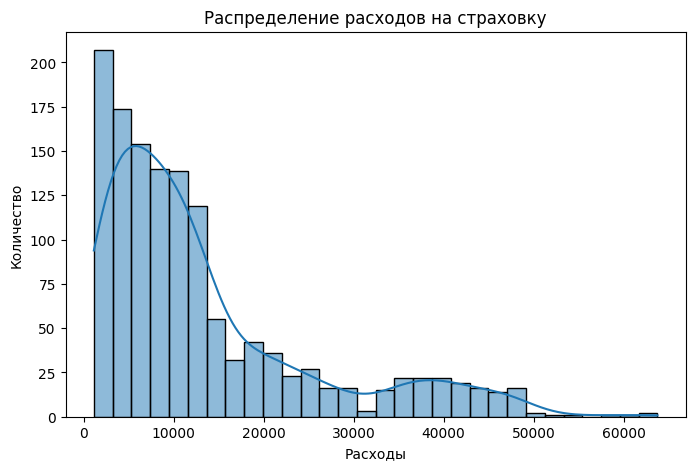

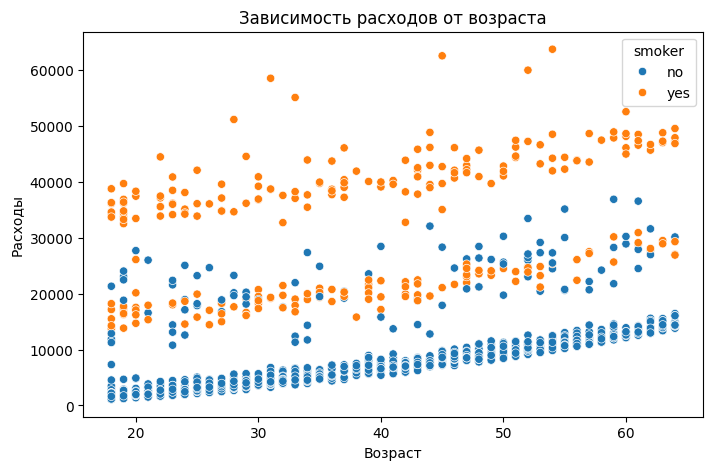

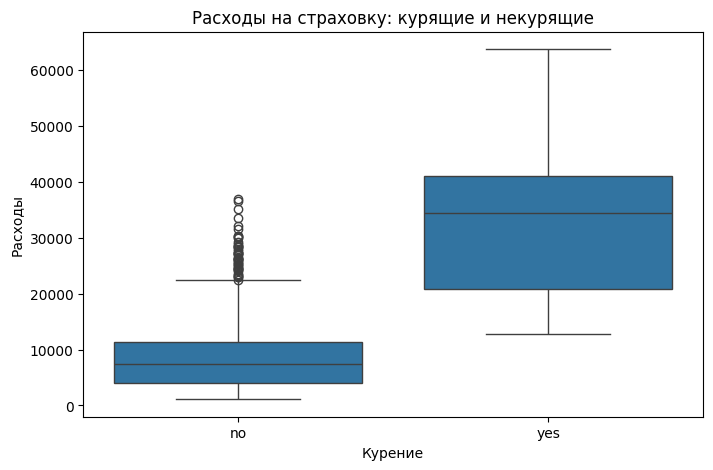

In [6]:
# 1. Распределение расходов на медицинскую страховку
plt.figure(figsize=(8, 5))
sns.histplot(df['charges'], bins=30, kde=True)
plt.title('Распределение расходов на страховку')
plt.xlabel('Расходы')
plt.ylabel('Количество')
plt.show()

# 2. Зависимость расходов от возраста
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='age', y='charges', hue='smoker')
plt.title('Зависимость расходов от возраста')
plt.xlabel('Возраст')
plt.ylabel('Расходы')
plt.show()

# 3. Расходы курящих и некурящих людей
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='smoker', y='charges')
plt.title('Расходы на страховку: курящие и некурящие')
plt.xlabel('Курение')
plt.ylabel('Расходы')
plt.show()